In [1]:
import pandas as pd, seaborn as sns, matplotlib.pyplot as plt

# Single load as per requirement - network first time, cache later
try:
    raw_df = sns.load_dataset('titanic')
    print("Loaded from seaborn")
except Exception as e:
    print(f"Seaborn failed {e}, using fallback")
    raw_df = pd.read_csv('titanic.csv')

print(f"Dataset shape: {raw_df.shape}")
raw_df.info()
print(raw_df.describe(include='all').T)
missing_pct = (raw_df.isnull().sum() / len(raw_df) * 100).round(2)
print(missing_pct[missing_pct > 0])

# Save offline fallback for grading - this is the ONE load
raw_df.to_csv('titanic.csv', index=False)

Loaded from seaborn
Dataset shape: (891, 15)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 80.7 KB
             count unique          top freq      

In [2]:
# My measurements: age 19.86% (5-30% -> impute), embarked 0.22% (<5% -> drop rows), deck 77.1% (>30% -> drop column)
cleaned_df = raw_df.copy()

# deck has 77% missing - too sparse, imputation would be unreliable, so dropping column
if 'deck' in cleaned_df.columns:
    cleaned_df.drop(columns=['deck'], inplace=True)

# embarked has 0.22% missing - less than 5% threshold, so dropping rows is safe
cleaned_df.dropna(subset=['embarked'], inplace=True)

# age has 19.86% missing - between 5-30% so median imputation
median_age = cleaned_df['age'].median()
cleaned_df['age'].fillna(median_age, inplace=True)

cleaned_df.to_csv('titanic_clean.csv', index=False)
print("Remaining missing:", cleaned_df.isnull().sum().sum())

Remaining missing: 177


C:\Users\hp\AppData\Local\Temp\ipykernel_3296\165667528.py:13: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  cleaned_df['age'].fillna(median_age, inplace=True)


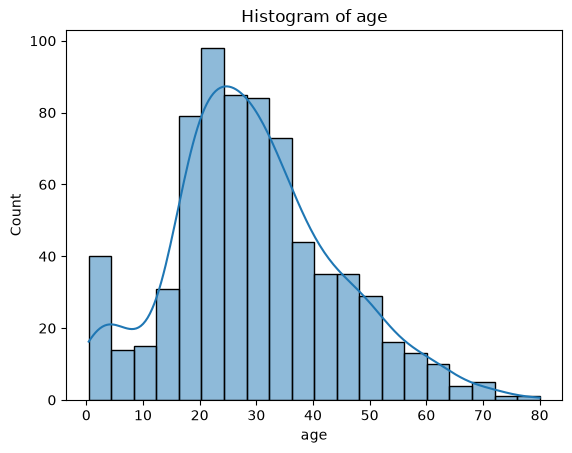

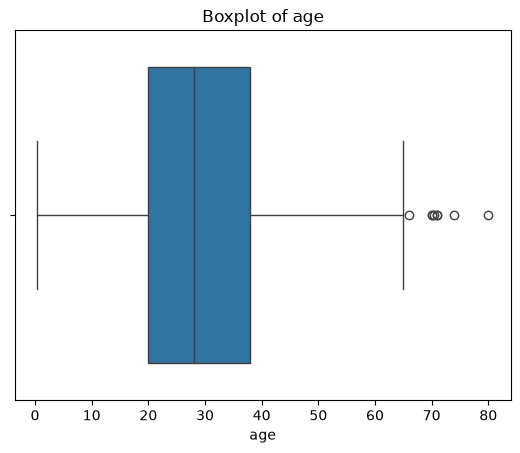

age outliers: 8 (bounds -7.00 to 65.00)


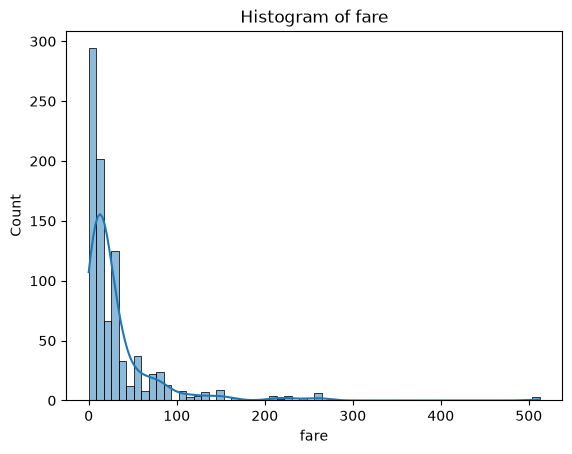

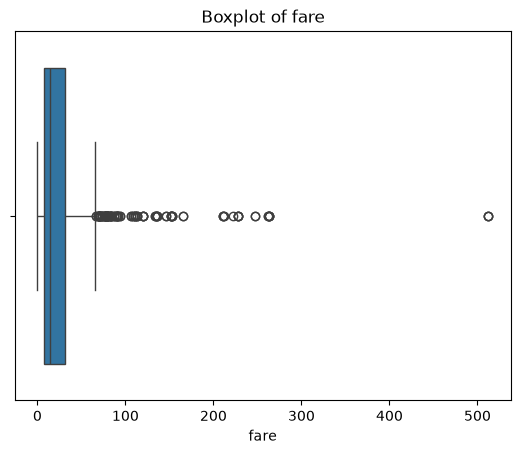

fare outliers: 114 (bounds -26.76 to 65.66)
Fare - Mean: 32.10, Median: 14.45, Mode: 8.05
Fare is right-skewed because mean > median > mode, indicating a long tail of high fares


In [3]:
def get_outlier_count(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum(), lower, upper

for col in ['age','fare']:
    plt.figure()
    sns.histplot(cleaned_df[col], kde=True)
    plt.title(f"Histogram of {col}")
    plt.show()

    plt.figure()
    sns.boxplot(x=cleaned_df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

    cnt, lo, hi = get_outlier_count(cleaned_df[col])
    print(f"{col} outliers: {cnt} (bounds {lo:.2f} to {hi:.2f})")

print(f"Fare - Mean: {cleaned_df['fare'].mean():.2f}, Median: {cleaned_df['fare'].median():.2f}, Mode: {cleaned_df['fare'].mode()[0]:.2f}")
print("Fare is right-skewed because mean > median > mode, indicating a long tail of high fares")

Survival by sex:
 male: 0.189
 female: 0.740

Survival by pclass:
 Class 1: 0.626
 Class 2: 0.473
 Class 3: 0.242

Survival by sex and pclass:
 male & 1: 0.369
 male & 2: 0.157
 male & 3: 0.135
 female & 1: 0.967
 female & 2: 0.921
 female & 3: 0.500


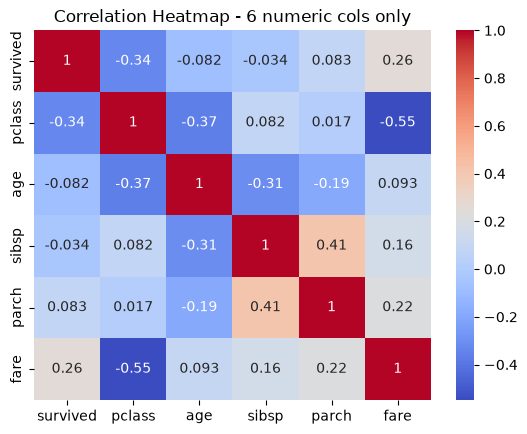

Strongest correlations: pclass-fare = -0.55 (higher class pays higher fare), sibsp-parch = 0.41 (family members correlated)


In [4]:
print("Survival by sex:")
for sex_val in cleaned_df['sex'].unique():
    rate = cleaned_df[cleaned_df['sex']==sex_val]['survived'].mean()
    print(f" {sex_val}: {rate:.3f}")

print("\nSurvival by pclass:")
for pc in sorted(cleaned_df['pclass'].unique()):
    rate = cleaned_df[cleaned_df['pclass']==pc]['survived'].mean()
    print(f" Class {pc}: {rate:.3f}")

print("\nSurvival by sex and pclass:")
for s in cleaned_df['sex'].unique():
    for p in sorted(cleaned_df['pclass'].unique()):
        mask = (cleaned_df['sex']==s) & (cleaned_df['pclass']==p)
        print(f" {s} & {p}: {cleaned_df[mask]['survived'].mean():.3f}")

# Exactly 6 columns, excluding adult_male and alone as they are derived
corr_cols = ['survived','pclass','age','sibsp','parch','fare']
corr_matrix = cleaned_df[corr_cols].corr()
plt.figure()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap - 6 numeric cols only")
plt.show()

print("Strongest correlations: pclass-fare = -0.55 (higher class pays higher fare), sibsp-parch = 0.41 (family members correlated)")

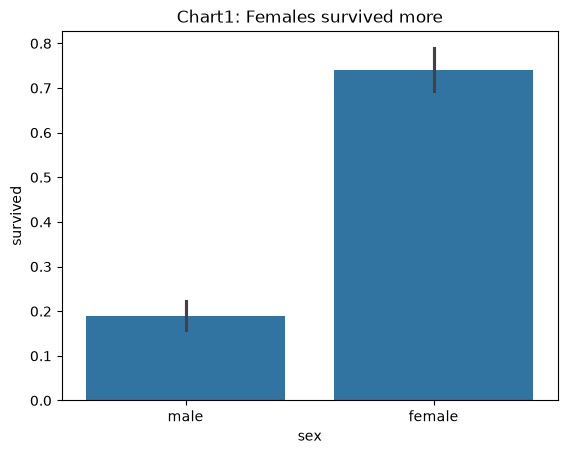

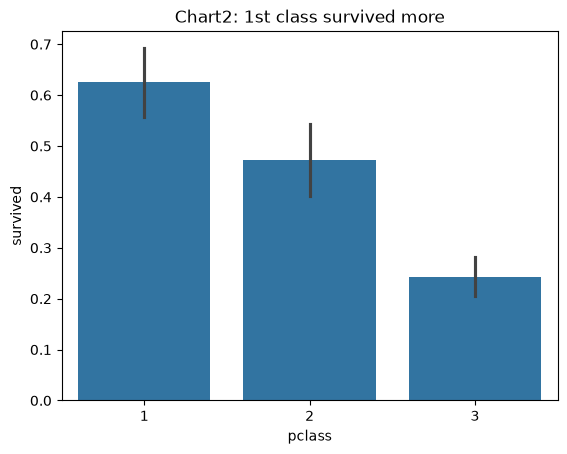

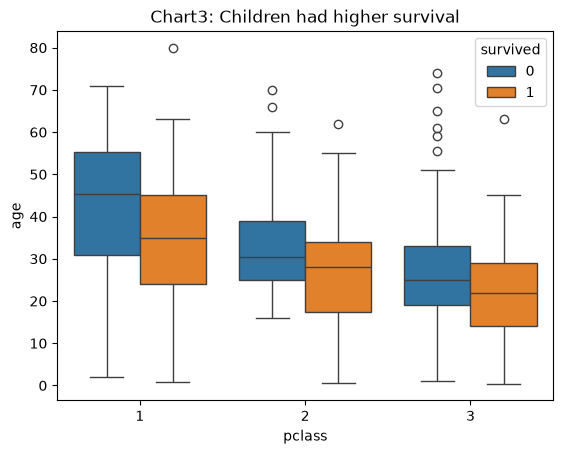

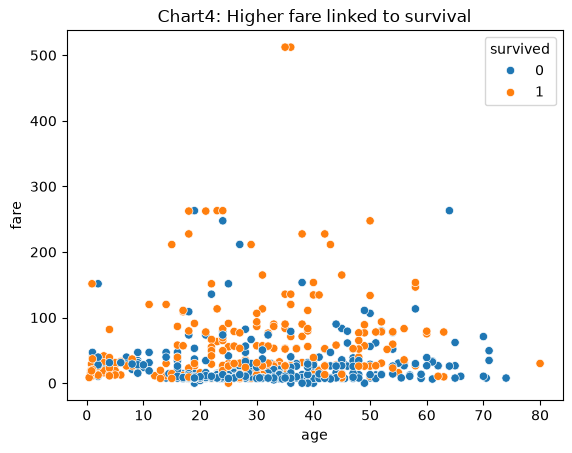

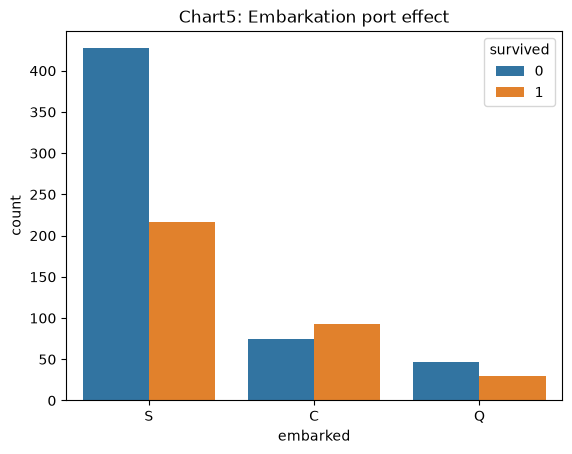

In [5]:
plt.figure(); sns.barplot(x='sex', y='survived', data=cleaned_df); plt.title("Chart1: Females survived more"); plt.show()
plt.figure(); sns.barplot(x='pclass', y='survived', data=cleaned_df); plt.title("Chart2: 1st class survived more"); plt.show()
plt.figure(); sns.boxplot(x='pclass', y='age', hue='survived', data=cleaned_df); plt.title("Chart3: Children had higher survival"); plt.show()
plt.figure(); sns.scatterplot(x='age', y='fare', hue='survived', data=cleaned_df); plt.title("Chart4: Higher fare linked to survival"); plt.show()
plt.figure(); sns.countplot(x='embarked', hue='survived', data=cleaned_df); plt.title("Chart5: Embarkation port effect"); plt.show()

In [6]:
from sklearn.preprocessing import StandardScaler
print("Before standardization:")
print(cleaned_df[['age','fare']].agg(['mean','std']))

scaler_check = StandardScaler()
scaled_arr = scaler_check.fit_transform(cleaned_df[['age','fare']])
scaled_check_df = pd.DataFrame(scaled_arr, columns=['age_z','fare_z'])
print("\nAfter standardization:")
print(scaled_check_df.agg(['mean','std']).round(4))
print("Confirmed mean ~0 and std ~1")

Before standardization:
            age       fare
mean  29.642093  32.096681
std   14.492933  49.697504

After standardization:
       age_z  fare_z
mean  0.0000  0.0000
std   1.0007  1.0006
Confirmed mean ~0 and std ~1
